# 02 — Transfer Learning (Fine-Tuned Pretrained Model)

**Project:** Bangladeshi Freshwater Fish Image Classification Using CNN and Transfer Learning
**Dataset:** BFF-15 (15 classes)
**Owner:** Mansi Somani

## What this notebook does

1. Loads the frozen train/val/test splits from `data/splits/`.
2. Uses the shared pipeline in `data_utils.py` (no re-splitting, no re-augmentation).
3. Loads a pretrained model (MobileNetV2 by default).
4. Adds a preprocessing layer so the pretrained weights receive the input
   distribution they were trained on.
5. Trains the new head first, then fine-tunes selected base layers at a lower LR.
6. Saves all artifacts into `transfer_learning/`:
   - `transfer_learning/logs/training_log.csv`
   - `transfer_learning/best_model/best.keras`
   - `transfer_learning/plots/`
   - `transfer_learning/metrics/final_metrics.json` and `confusion_matrix.csv`

Notebook 03 will read these to compare against the from-scratch CNN.

## Contract (must not change)

- Class mapping: `CLASS_NAMES` from `data_utils`.
- Splits: loaded from `data_utils.load_splits()`.
- Augmentation: `data_utils.get_train_ds()` only.
- Input normalization: `[0, 1]` from `data_utils`. The pretrained preprocessing
  is applied **inside the model** as a `Rescaling(2.0, offset=-1.0)` layer (this Keras 3 MobileNetV2 has no built-in preprocessing, so we add it).
- Image size: 224 × 224.
- Seed: 42.

In [5]:
import sys, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers

# PROJECT_ROOT comes from data_utils.__file__, not from the notebook's cwd, so
# artifacts land in the same place locally, in VS Code and in Colab.
sys.path.append(str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from data_utils import (
    PROJECT_ROOT,
    get_train_ds, get_val_ds, get_test_ds, get_class_weights,
    CLASS_NAMES, CLASS_TO_IDX, IDX_TO_CLASS,
    IMG_SIZE, BATCH_SIZE, SEED,
)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Num classes:", len(CLASS_NAMES))

TensorFlow: 2.21.0
Num classes: 15


## Runtime and long-run safety

This runs on Google Colab, where a T4 session is reclaimed after roughly 12 hours and drops on ~90 minutes of idle. `ModelCheckpoint(save_best_only=True)` keeps only the winning weights and discards the epoch counter and optimiser state, so a dropped session would otherwise mean starting over.

`ResumeFromCheckpoint` writes the live weights and the epoch count after every epoch to `best_model/last_state.kerasresumable`. Re-run the notebook after a drop and training continues from there. Phase 1 and phase 2 share one resume slot, and the epoch count lives in the same JSON sidecar, so the hand-off between the two phases survives an interruption.


In [6]:
physical = tf.config.list_physical_devices("GPU")
if physical:
    try:                                   # don't grab all VRAM: colab notebooks share the T4
        for g in physical:
            tf.config.experimental.set_memory_growth(g, True)
    except Exception as exc:
        print("memory growth not set:", exc)
print("GPU:", physical[0].name if physical else "CPU only - move to Runtime > Change runtime type > T4")


GPU: /physical_device:GPU:0


In [7]:
TL_DIR       = PROJECT_ROOT / "transfer_learning"
LOGS_DIR     = TL_DIR / "logs"
PLOTS_DIR    = TL_DIR / "plots"
METRICS_DIR  = TL_DIR / "metrics"
CKPT_DIR     = TL_DIR / "best_model"

for d in [LOGS_DIR, PLOTS_DIR, METRICS_DIR, CKPT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

LOG_CSV      = LOGS_DIR / "training_log.csv"
CKPT_PATH    = CKPT_DIR / "best.keras"
METRICS_JSON = METRICS_DIR / "final_metrics.json"
CM_CSV       = METRICS_DIR / "confusion_matrix.csv"
RESUME_PATH  = CKPT_DIR / "last_state.kerasresumable"

print("Artifacts folder:", TL_DIR)

Artifacts folder: /content/transfer_learning


In [8]:
train_ds = get_train_ds()
val_ds   = get_val_ds()
test_ds  = get_test_ds()

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val   batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test  batches:", tf.data.experimental.cardinality(test_ds).numpy())

Train batches: 115
Val   batches: 25
Test  batches: 25


## Model selection

We use **MobileNetV2** as the default pretrained backbone. Alternatives that
work in TensorFlow 2.21 with weights on ImageNet:

- `DenseNet121`
- `EfficientNetB0`
- `ResNet50V2`
- `InceptionV3`

To switch, change the base model call below and replace the preprocessing layer
with the one that backbone expects.

**Important:** `data_utils` gives us `[0, 1]` inputs and every pretrained model
expects a different range. MobileNetV2 wants `[-1, 1]`, so one `Rescaling(2.0,
offset=-1.0)` layer does the whole job - exactly what its `preprocess_input`
computes on `[0, 1]` data, but serialisable. `DenseNet121` / `ResNet50V2` instead
want `x * 255` followed by their own caffe/tf preprocessing, so switching means
changing this layer, not just the model name. Both model notebooks therefore
consume identical tensors from `data_utils`.


In [9]:
BASE_NAME = "MobileNetV2"

base = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet",
)
base.trainable = False                      # phase 1: only the new head learns

inputs = layers.Input(shape=(*IMG_SIZE, 3), name="image")          # [0, 1] from data_utils
# MobileNetV2.preprocess_input maps [0,255] -> [-1,1]. On [0,1] input that is x*2-1.
# Rescaling does exactly this and, unlike Lambda, saves/loads cleanly in .keras files.
x = layers.Rescaling(scale=2.0, offset=-1.0, name="pretrained_preprocess")(inputs)
x = base(x, training=False)                 # keep BatchNorm in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASS_NAMES), activation="softmax", name="classifier")(x)

tl_model = models.Model(inputs, outputs, name="mobilenetv2_transfer")
tl_model.compile(
    optimizer=optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
tl_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pretrained_preprocess           │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Phase 1 - train the new head (base frozen)

In [10]:
import time
from eval_utils import ResumeFromCheckpoint

class_weights = get_class_weights()
# One resume slot shared by both phases; the epoch counter lives in its JSON sidecar.
resume_cb = ResumeFromCheckpoint(RESUME_PATH)
p1_start = resume_cb.epoch_ran
t0 = time.time()

# ---------------- Phase 1: train the head, base frozen ----------------
P1_EPOCHS = 15
cbs1 = [
    callbacks.ModelCheckpoint(str(CKPT_PATH), monitor="val_accuracy", mode="max", save_best_only=True, verbose=1),
    resume_cb,                                              # survives a dropped Colab session
    callbacks.CSVLogger(str(LOG_CSV), append=p1_start > 0),
    callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=5, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
]
h1 = tl_model.fit(train_ds, validation_data=val_ds,
                  initial_epoch=p1_start, epochs=P1_EPOCHS,
                  class_weight=class_weights, callbacks=cbs1)
p1_epochs = len(h1.epoch) + p1_start
p1_best = max(h1.history["val_accuracy"])
print(f"Phase 1 done: {p1_epochs} epochs, best val_acc = {p1_best:.4f}")

Epoch 1/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - accuracy: 0.4074 - loss: 1.9358
Epoch 1: val_accuracy improved from None to 0.86079, saving model to /content/transfer_learning/best_model/best.keras

Epoch 1: finished saving model to /content/transfer_learning/best_model/best.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 67s 461ms/step - accuracy: 0.6097 - loss: 1.2739 - val_accuracy: 0.8608 - val_loss: 0.5451 - learning_rate: 0.0010
Epoch 2/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - accuracy: 0.8489 - loss: 0.5098
Epoch 2: val_accuracy improved from 0.86079 to 0.88633, saving model to /content/transfer_learning/best_model/best.keras

Epoch 2: finished saving model to /content/transfer_learning/best_model/best.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 38s 325ms/step - accuracy: 0.8528 - loss: 0.4653 - val_accuracy: 0.8863 - val_loss: 0.3843 - learning_rate: 0.0010
Epoch 3/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - accuracy: 0.8954 - loss: 0.3522
Epoch 3: val_accuracy improved from 0.886

## Phase 2 - fine-tune the top 30 layers of the base at a low learning rate
BatchNorm layers stay frozen; this is the standard recipe for small datasets.

In [11]:
# ---------------- Phase 2: fine-tune top of the base at a low LR ----------------
FINE_TUNE_LAYERS = 30
base.trainable = True
for layer in base.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base.layers:                         # never unfreeze BatchNorm (small dataset, small batches)
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

tl_model.compile(                                 # must re-compile after changing trainable flags
    optimizer=optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Trainable params now:", sum(int(np.prod(w.shape)) for w in tl_model.trainable_weights))

P2_EPOCHS = 20
# resume_cb.epoch_ran is p1_epochs on a clean phase-2 restart, so p2_start keeps the old behaviour
p2_start = max(resume_cb.epoch_ran, p1_epochs)

cbs2 = [
    # initial_value_threshold: only overwrite best.keras if phase 2 beats phase 1
    callbacks.ModelCheckpoint(str(CKPT_PATH), monitor="val_accuracy", mode="max", save_best_only=True,
                              initial_value_threshold=p1_best, verbose=1),
    resume_cb,                                              # survives a dropped Colab session
    callbacks.CSVLogger(str(LOG_CSV), append=True),          # same file, epochs continue
    callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=6, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
]
h2 = tl_model.fit(train_ds, validation_data=val_ds,
                  initial_epoch=p2_start, epochs=p2_start + P2_EPOCHS,
                  class_weight=class_weights, callbacks=cbs2)
train_seconds = time.time() - t0
# len(h2.epoch) ALREADY includes phase 1: fit(initial_epoch=N) reports epochs N..end.
# Adding p1_epochs again overstated the epoch count in the comparison table.
epochs_ran = max(len(h2.epoch), p2_start)

# Captured now, before load_model(). After reloading a .keras checkpoint Keras marks
# every layer trainable again, so measuring later would report ~3.5M trainable params
# for a model that only fine-tuned the top 30 layers.
trainable_params = int(sum(int(np.prod(w.shape)) for w in tl_model.trainable_weights))

# p1_best guards phase 2's initial_value_threshold; persist it for the same reason
json.dump({"p1_epochs": p1_epochs, "p1_best": p1_best, "epochs_ran": epochs_ran,
           "train_seconds": train_seconds, "trainable_params": trainable_params},
          open(METRICS_DIR / "phase_history.json", "w"), indent=2)

print(f"Total: {epochs_ran} epochs in {train_seconds/60:.1f} min")
print(f"Trainable at end of fine-tune: {trainable_params:,}")

Trainable params now: 1529935
ResumeFromCheckpoint: restored last_state.weights.h5 at epoch 15
Epoch 16/35


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.9627 - loss: 0.0989
Epoch 16: val_accuracy did not improve from 0.95275
115/115 ━━━━━━━━━━━━━━━━━━━━ 60s 411ms/step - accuracy: 0.9620 - loss: 0.1057 - val_accuracy: 0.9527 - val_loss: 0.1405 - learning_rate: 1.0000e-05
Epoch 17/35
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step - accuracy: 0.9683 - loss: 0.0837
Epoch 17: val_accuracy improved from 0.95275 to 0.95658, saving model to /content/transfer_learning/best_model/best.keras

Epoch 17: finished saving model to /content/transfer_learning/best_model/best.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 38s 334ms/step - accuracy: 0.9647 - loss: 0.0931 - val_accuracy: 0.9566 - val_loss: 0.1247 - learning_rate: 1.0000e-05
Epoch 18/35
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step - accuracy: 0.9732 - loss: 0.0785
Epoch 18: val_accuracy improved from 0.95658 to 0.95913, saving model to /content/transfer_learning/best_model/best.keras

Epoch 18: finished saving model to /content/transfer_learning/best_

## Evaluate on the test set

In [12]:
# Evaluation lives in eval_utils.py and is shared with 01_custom_cnn, so the two
# folders cannot drift into different schemas - 03_comparison reads both.
# Same artifact paths and same final_metrics.json keys as before.
from eval_utils import evaluate_and_save, plot_curves


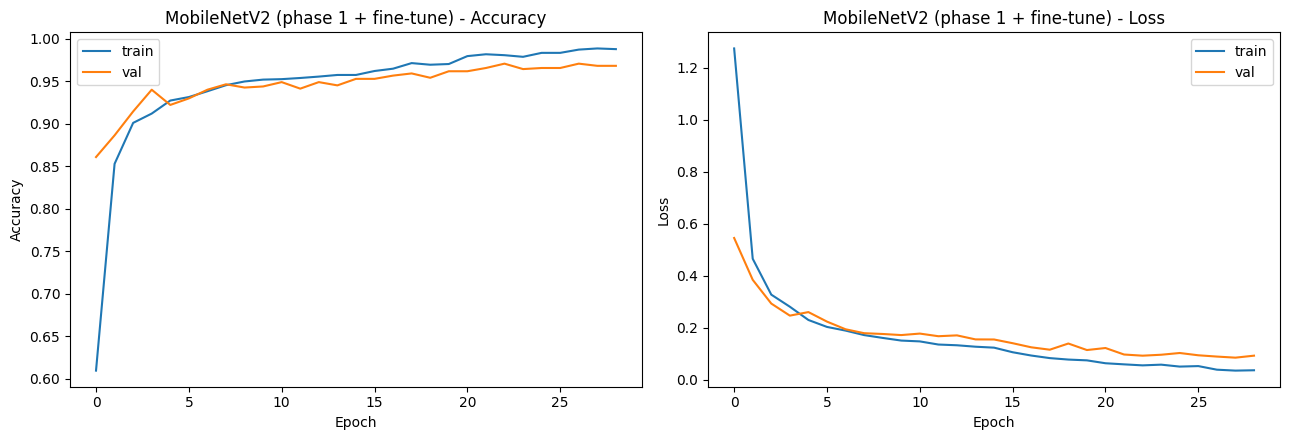

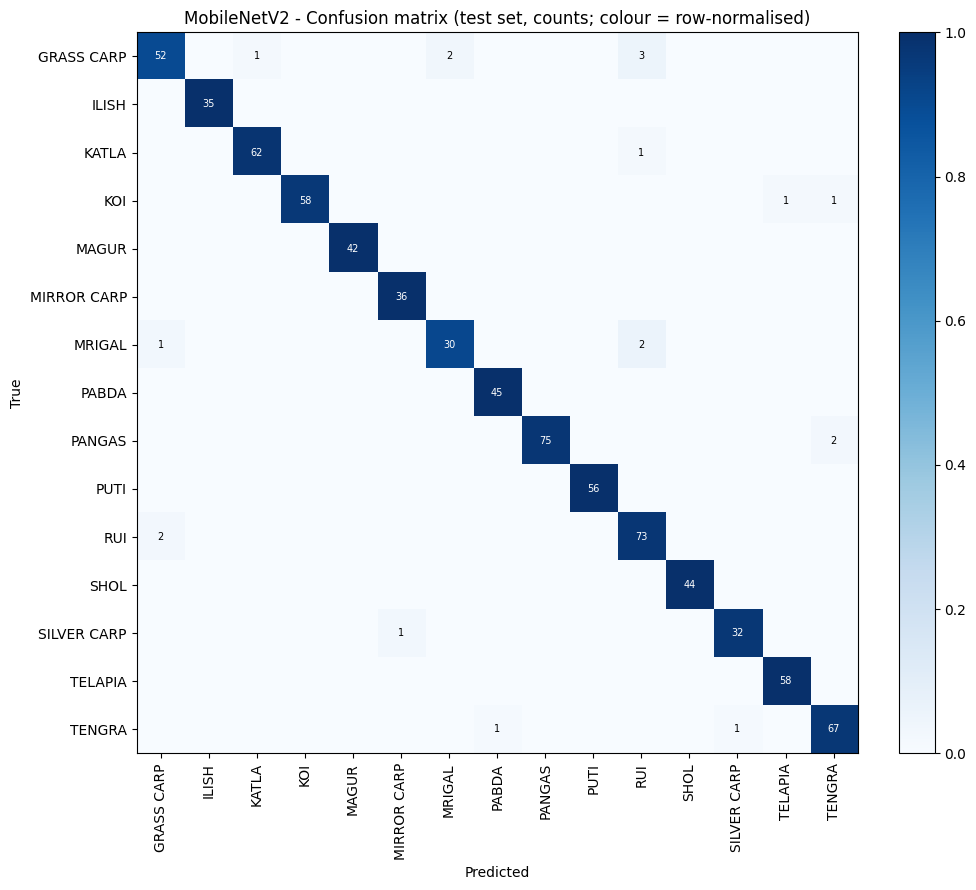

Test accuracy : 0.9758
Top-5 accuracy: 1.0000
Macro  P/R/F1 : 0.9768 / 0.9763 / 0.9764
Weight P/R/F1 : 0.9760 / 0.9758 / 0.9757
             precision  recall     f1  support
GRASS CARP       0.945   0.897  0.920     58.0
ILISH            1.000   1.000  1.000     35.0
KATLA            0.984   0.984  0.984     63.0
KOI              1.000   0.967  0.983     60.0
MAGUR            1.000   1.000  1.000     42.0
MIRROR CARP      0.973   1.000  0.986     36.0
MRIGAL           0.938   0.909  0.923     33.0
PABDA            0.978   1.000  0.989     45.0
PANGAS           1.000   0.974  0.987     77.0
PUTI             1.000   1.000  1.000     56.0
RUI              0.924   0.973  0.948     75.0
SHOL             1.000   1.000  1.000     44.0
SILVER CARP      0.970   0.970  0.970     33.0
TELAPIA          0.983   1.000  0.991     58.0
TENGRA           0.957   0.971  0.964     69.0


In [13]:
plot_curves(LOG_CSV, f"{BASE_NAME} (phase 1 + fine-tune)", PLOTS_DIR / "training_curves.png")

best = tf.keras.models.load_model(CKPT_PATH)   # the winning checkpoint, not the last epoch
tl_metrics = evaluate_and_save(
    best, test_ds, BASE_NAME, epochs_ran, train_seconds,
    METRICS_JSON, CM_CSV, PLOTS_DIR / "confusion_matrix.png",
    trainable_params=trainable_params,
    extra_metrics={"phase1_epochs": p1_epochs, "phase2_epochs": epochs_ran - p1_epochs,
                   "fine_tune_layers": FINE_TUNE_LAYERS},
)
